# Part load — current ramps, cell voltage, heating, exhaust trips (all 39 days)

**Part load** is every minute with string current between 1 A and 28.5 A (`../01_docs/operational-modes.md` §1). Rated
power (≈ 30 A per string, 60 kW DC) is never reached, so these are the only load minutes in the data: **10 short
runs, all in March 2026**, most of them ended by a safety trip.

This notebook covers:

1. **Inventory**: every run, its peak current and power, and how it ended.
2. **Load profile and ramp rates** against the 1 A/min limit.
3. **Electrical behaviour**: string voltage against current, the lowest cell voltage and its protection limit,
   and the balance between the five strings.
4. **Heating under load**: stack temperature, thermocouple spread, and the exhaust temperature that trips the plant.
5. **Fuel, air and heater** during load, fuel utilisation and an approximate DC efficiency.
6. **How runs end**, and 7. **how far rated power is**.
8. **Signal levels by current band** (input for synthetic data).

**Data:** labels and episodes from `04_synthetic_data/library/` (rebuilt 2026-10-14), extra signals from
`02_data/downsampled/*_10s.parquet` via `stage_signals.py` at 1 min, safety events from
`operating_states/trip_cut_events.csv` (`trip_check.py`). String current and voltage are the PLC monitor columns
(`PLC_hostSetp_ctrl_ctEIRC4X_rCurrMonitor / rVoltMonitor`), as in `operating_states.py`. Tables and figures are
saved to `part_load/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops
import stage_signals as ss

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

OUT = Path("part_load")
OUT.mkdir(exist_ok=True)
RAMP_LIMIT = 1.0  # A/min per stack (Elcogen p.14, p.17–18, p.21)
I_RATED = 30.0  # A per string, nominal
P_RATED_DC = 60.0  # kW DC
EXH_LIMIT = (
    200.0  # °C, exhaust trip TIRZ_8_1_10 from 2026-01-28 (300 °C from 2026-03-27)
)
NG_KW_PER_LNMIN = 9.97 * 0.06  # kW of CH4 lower heating value per ln/min (9.97 kWh/Nm³)
PRE, POST = pd.Timedelta("30min"), pd.Timedelta("45min")
STRING_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8f5bd6"]
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.4,
        "font.size": 9,
    }
)

## 1. Load labels, signals, episodes and safety events

In [2]:
d = ss.load()
e = ss.neighbours(ss.episodes())
pl = e[e.stage == "Part load"].copy()
s = d[d.stage == "Part load"]
tev = ss.all_cuts()
tev["time"] = pd.to_datetime(tev["time"])
I_COLS = [f"PLC_hostSetp_ctrl_ctEIRC4{i}_rCurrMonitor" for i in ss.STRINGS]
V_COLS = [f"PLC_hostSetp_ctrl_ctEIRC4{i}_rVoltMonitor" for i in ss.STRINGS]
d["exhaust_C"] = d.TIRZ_8_1_10
d["eff_dc"] = d.P_stack_kW / (d.fuel * NG_KW_PER_LNMIN)
s = d[d.stage == "Part load"]
print(
    f"{len(s)} Part load minutes ({len(s) / 60:.1f} h, {len(s) / len(d):.2%} of "
    f"logged time) in {len(pl)} runs, "
    f"days: {', '.join(sorted(pl.start.dt.strftime('%m-%d').unique()))}"
)

268 Part load minutes (4.5 h, 0.49% of logged time) in 10 runs, days: 03-13, 03-19, 03-24, 03-25, 03-30


## 2. Inventory of load runs

`end_event` lists the safety events from 2 min before to 15 min after the last load minute. `exhaust_max_C` is the
highest exhaust temperature `TIRZ_8_1_10` in the same window (trip value 200 °C until 2026-03-27).

In [3]:
rows = []
for _, r in pl.iterrows():
    g = d[d.episode_id == r.episode_id]
    end = g.index[-1]
    w = d.loc[g.index[0] : end + pd.Timedelta("15min")]
    te = tev[
        (tev.time >= end - pd.Timedelta("2min"))
        & (tev.time <= end + pd.Timedelta("15min"))
    ]
    rows.append(
        {
            "episode_id": r.episode_id,
            "start": g.index[0],
            "minutes": len(g),
            "prev": r.prev_stage,
            "next": r.next_stage,
            "I_max_A": g.I_string_A.max(),
            "P_max_kW": g.P_stack_kW.max(),
            "share_of_rated": g.P_stack_kW.max() / P_RATED_DC,
            "T_start_C": g.T_stack_C.iloc[0],
            "T_end_C": g.T_stack_C.iloc[-1],
            "T_rise_K": g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0],
            "exhaust_start_C": g.exhaust_C.iloc[0],
            "exhaust_max_C": w.exhaust_C.max(),
            "V_cell_min_V": g.V_cell_min.min(),
            "ends_in_trip": r.ends_in_trip,
            "end_event": "; ".join(
                f"{t.time:%H:%M} {t.kind}" for _, t in te.iterrows()
            ),
        }
    )
inv = pd.DataFrame(rows).set_index("episode_id")
inv.round(2).to_csv(OUT / "runs.csv")
inv.round(2)

C:\Users\mrgur\AppData\Local\Temp\ipykernel_27668\2067213649.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  inv.round(2).to_csv(OUT / "runs.csv")
C:\Users\mrgur\AppData\Local\Temp\ipykernel_27668\2067213649.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  inv.round(2)


,start,minutes,prev,next,I_max_A,P_max_kW,share_of_rated,T_start_C,T_end_C,T_rise_K,exhaust_start_C,exhaust_max_C,V_cell_min_V,ends_in_trip,end_event
episode_id,,,,,,,,,,,,,,,
20260313_1003_Part,2026-03-13 10:03:00,8,Hot standby,Thermal adjustment,4.58,10.92,0.18,595.50,602.97,7.47,118.60,123.35,0.89,False,10:10 Valve change only
20260313_1326_Part,2026-03-13 13:26:00,17,Hot standby,Shut-down,8.32,19.09,0.32,654.91,677.40,22.50,131.12,200.49,0.83,True,"13:45 Power cut at trip value, gas unchanged"
20260319_1020_Part,2026-03-19 10:20:00,17,Hot standby,Thermal adjustment,6.42,15.03,0.25,589.80,608.72,18.93,118.30,200.34,0.86,True,10:36 Valve change only; 10:40 Valve change on...
20260319_1531_Part,2026-03-19 15:31:00,18,Hot standby,Shut-down,9.08,21.17,0.35,606.80,629.52,22.72,127.61,199.50,0.86,True,"15:54 Power cut at trip value, gas unchanged"
20260324_0854_Part,2026-03-24 08:54:00,32,Hot standby,Thermal adjustment,14.58,31.15,0.52,598.39,656.73,58.34,99.89,200.69,0.71,True,09:25 EMERGENCY PURGE; 09:29 Load / heater off...
20260324_1354_Part,2026-03-24 13:54:00,43,Hot standby,Thermal adjustment,8.41,18.73,0.31,623.79,670.21,46.42,107.87,212.30,0.72,True,14:36 EMERGENCY PURGE; 14:38 EMERGENCY STOP
20260325_0818_Part,2026-03-25 08:18:00,33,Hot standby,Thermal adjustment,11.65,23.74,0.40,602.57,632.23,29.66,108.84,138.23,0.71,True,08:50 EMERGENCY STOP
20260325_1017_Part,2026-03-25 10:17:00,33,Hot standby,Thermal adjustment,12.26,25.02,0.42,614.40,656.98,42.58,111.00,197.39,0.71,True,"10:49 Gas to purge, heater kept on; 10:58 Powe..."
20260325_1430_Part,2026-03-25 14:30:00,44,Hot standby,Shut-down,16.23,33.59,0.56,587.43,675.39,87.95,104.71,197.69,0.72,True,"15:18 Gas to purge, heater kept on"


## 3. Load profile and ramp rates

### 3.1 Every run

Top: string current (mean of the five strings) and stack DC power. Bottom: lowest cell voltage of any string, its
protection limit (dashed), and the exhaust temperature (right axis) with its 200 °C trip value. Shaded = Part load
minutes; the window runs 30 min before to 45 min after.

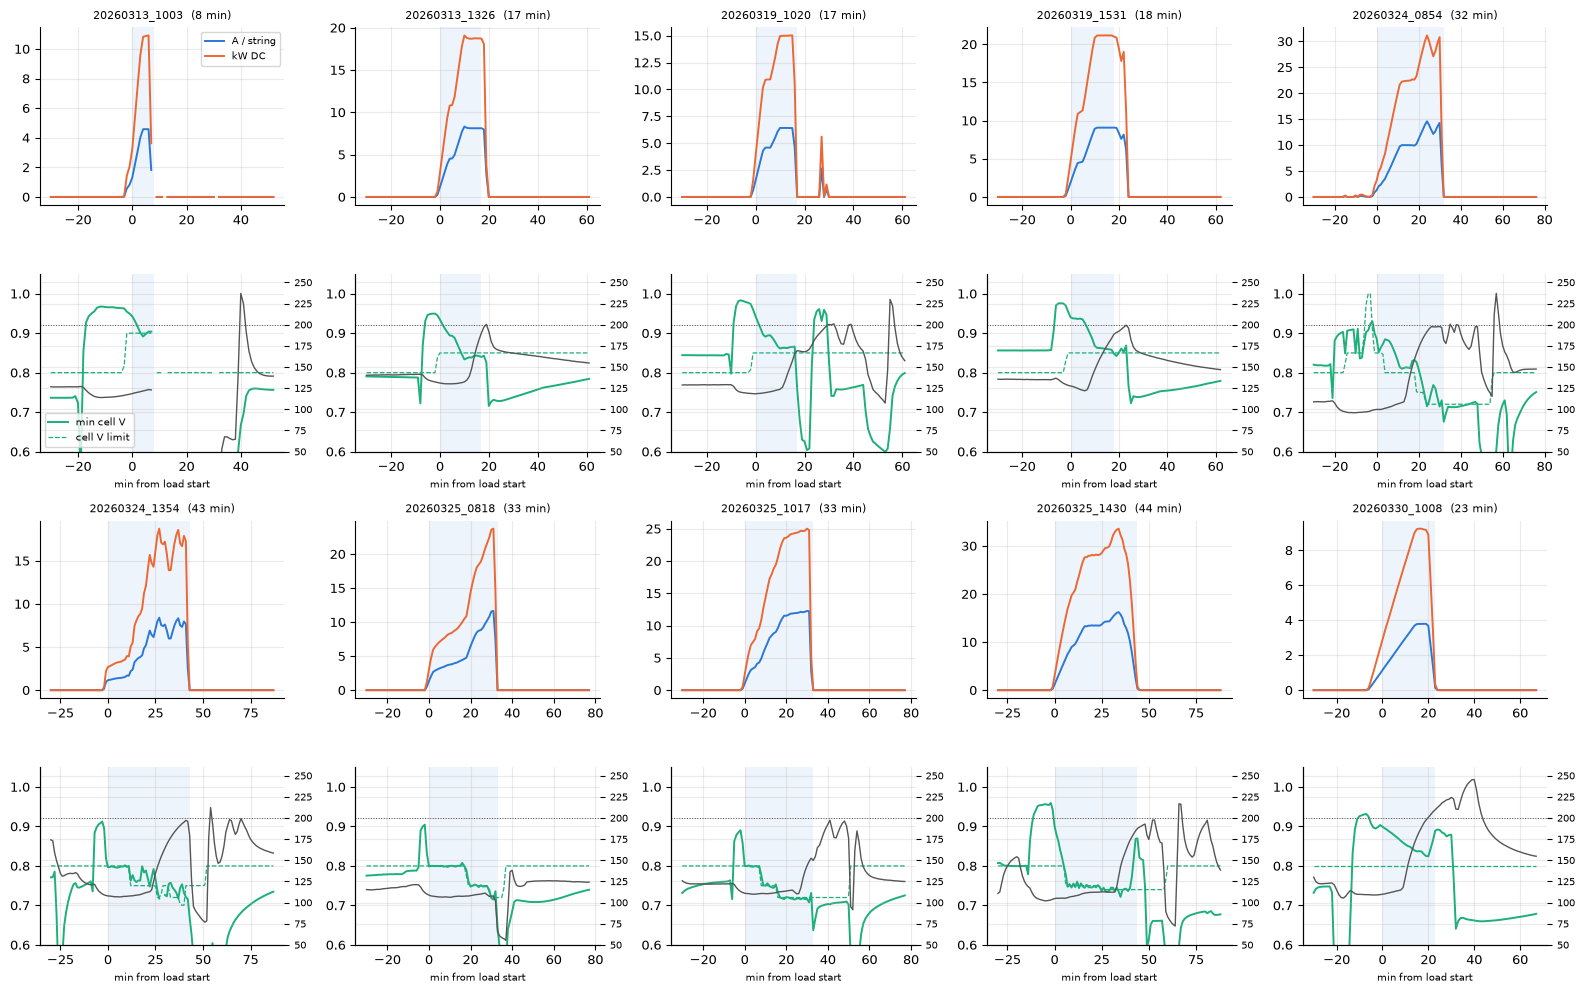

In [4]:
ids = list(pl.episode_id)
fig, axs = plt.subplots(4, 5, figsize=(16, 10), sharex=False)
for j, eid in enumerate(ids):
    g = d[d.episode_id == eid]
    t0 = g.index[0]
    w = d.loc[t0 - PRE : g.index[-1] + POST]
    m = (w.index - t0).total_seconds() / 60
    a = axs[2 * (j // 5), j % 5]
    b = axs[2 * (j // 5) + 1, j % 5]
    a.plot(m, w.I_string_A, color="#2a78d6", label="A / string")
    a.plot(m, w.P_stack_kW, color="#eb6834", label="kW DC")
    a.set_title(f"{eid[:13]}  ({len(g)} min)", fontsize=8)
    b.plot(m, w.V_cell_min, color="#1baf7a", label="min cell V")
    b.plot(m, w.V_cell_min_sp, color="#1baf7a", ls="--", lw=0.9, label="cell V limit")
    b.set_ylim(0.6, 1.05)
    bb = b.twinx()
    bb.plot(m, w.exhaust_C, color="#555", lw=1, label="exhaust °C")
    bb.axhline(EXH_LIMIT, color="#555", lw=0.7, ls=":")
    bb.set_ylim(50, 260)
    bb.tick_params(labelsize=7)
    for x in (a, b):
        x.axvspan(0, len(g), color="#2a78d6", alpha=0.08, lw=0)
    b.set_xlabel("min from load start", fontsize=7)
axs[0, 0].legend(fontsize=7)
axs[1, 0].legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(OUT / "runs_overview.png", dpi=120)
plt.show()

### 3.2 Ramp rates against the 1 A/min limit

Current ramp per string from a 4-minute centred difference of the 1-min mean (as in `operational-modes.md` §4.4),
counting only |dI/dt| > 0.05 A/min. The power ramp is the 1-min difference of the stack DC power.

In [5]:
dI = s.dIdt_A_per_min
dP = s.P_stack_kW.diff()[s.index.to_series().diff() == pd.Timedelta("1min")]
rows = []
for eid, g in s.groupby("episode_id"):
    up, dn = (
        g.dIdt_A_per_min[g.dIdt_A_per_min > 0.05],
        g.dIdt_A_per_min[g.dIdt_A_per_min < -0.05],
    )
    p = dP.reindex(g.index)
    rows.append(
        {
            "episode_id": eid,
            "up_median": up.median(),
            "up_p95": up.quantile(0.95),
            "up_max": up.max(),
            "down_median": dn.median(),
            "down_min": dn.min(),
            "minutes_over_limit": int((g.dIdt_A_per_min.abs() > RAMP_LIMIT).sum()),
            "P_up_p95_kW_per_min": p.quantile(0.95),
            "P_down_min_kW_per_min": p.min(),
        }
    )
rr = pd.DataFrame(rows).set_index("episode_id")
up_all, dn_all = dI[dI > 0.05], dI[dI < -0.05]
rr.loc["all runs"] = [
    up_all.median(),
    up_all.quantile(0.95),
    up_all.max(),
    dn_all.median(),
    dn_all.min(),
    int((dI.abs() > RAMP_LIMIT).sum()),
    dP.quantile(0.95),
    dP.min(),
]
rr.round(2).to_csv(OUT / "ramp_rates.csv")
rr.round(2)

,up_median,up_p95,up_max,down_median,down_min,minutes_over_limit,P_up_p95_kW_per_min,P_down_min_kW_per_min
episode_id,,,,,,,,
20260313_1003_Part,0.64,0.82,0.82,-0.85,-1.15,1.0,2.15,-7.29
20260313_1326_Part,0.60,0.87,0.91,NaN,NaN,0.0,2.20,-0.29
20260319_1020_Part,0.36,0.87,0.92,-1.60,-1.60,2.0,2.16,-4.59
20260319_1531_Part,0.67,0.89,0.89,NaN,NaN,0.0,2.21,-0.01
20260324_0854_Part,0.57,0.91,0.91,-1.01,-3.40,3.0,1.96,-18.97
20260324_1354_Part,0.30,0.58,0.72,-0.37,-1.99,3.0,1.85,-11.79
20260325_0818_Part,0.32,0.70,0.79,-2.70,-2.89,2.0,1.65,-9.49
20260325_1017_Part,0.46,0.75,0.80,-3.04,-3.07,3.0,1.69,-19.66
20260325_1430_Part,0.52,0.91,0.92,-1.33,-2.46,6.0,2.07,-6.24


**Ramp-down at the end of a run.** The 1-min data smooth a fast drop. The current in the last logged minutes of each
run, from the 10 s file, shows how fast the load actually fell.

In [6]:
rows = []
for _, r in pl.iterrows():
    g = d[d.episode_id == r.episode_id]
    day = g.index[-1].strftime("%Y%m%d")
    raw = pd.read_parquet(ss.SRC / f"{day}_10s.parquet", columns=["Date Time"] + I_COLS)
    raw.index = pd.to_datetime(raw.pop("Date Time"))
    i10 = raw.apply(pd.to_numeric, errors="coerce").clip(lower=0).mean(axis=1)
    w = i10.loc[
        g.index[-1] - pd.Timedelta("10min") : g.index[-1] + pd.Timedelta("5min")
    ]
    peak = w.idxmax()
    after = w.loc[peak:]
    zero = after[after < ops.I_LOAD]
    t_zero = zero.index[0] if len(zero) else None
    rows.append(
        {
            "episode_id": r.episode_id,
            "I_before_drop_A": w.max(),
            "drop_seconds": (t_zero - peak).total_seconds()
            if t_zero is not None
            else np.nan,
            "max_step_A_per_10s": -w.diff().min(),
            "A_per_min_over_drop": w.max() / ((t_zero - peak).total_seconds() / 60)
            if t_zero is not None and t_zero > peak
            else np.nan,
        }
    )
drop = pd.DataFrame(rows).set_index("episode_id")
drop.round(2).to_csv(OUT / "load_drop.csv")
drop.round(2)

,I_before_drop_A,drop_seconds,max_step_A_per_10s,A_per_min_over_drop
episode_id,,,,
20260313_1003_Part,4.59,330.0,2.07,0.83
20260313_1326_Part,8.39,550.0,3.57,0.92
20260319_1020_Part,6.42,410.0,4.49,0.94
20260319_1531_Part,9.09,NaN,0.16,NaN
20260324_0854_Part,14.75,430.0,8.20,2.06
20260324_1354_Part,8.53,310.0,6.38,1.65
20260325_0818_Part,11.83,40.0,8.30,17.74
20260325_1017_Part,12.40,70.0,5.96,10.63
20260325_1430_Part,16.27,580.0,0.47,1.68


## 4. Electrical behaviour

### 4.1 String voltage against current

The string voltage falls with current and rises with stack temperature (hotter cells have lower resistance), and the
stack heats during every run, so a fit on current alone mixes the two. For each string a plane
V = V₀ − R·I + k_T·(T − 620 °C) is fitted over the Part load minutes above 2 A. V₀ is the voltage at 620 °C
extrapolated to zero current, R the effective resistance (ohmic plus activation and diffusion losses, linearised over
2–16 A), k_T the temperature gain. Minutes where the converter is connecting or disconnecting (string voltage
< 350 V) are left out.

In [7]:
T_REF = 620.0


def plane(y, i, t):
    A = np.column_stack([np.ones(len(i)), -i, t - T_REF])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    r2 = 1 - ((y - A @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return coef, r2


rows = []
for i, (ic, vc) in enumerate(zip(I_COLS, V_COLS), start=1):
    x = s[[ic, vc, "T_stack_C"]].dropna()
    x = x[(x[ic] > 2) & (x[vc] > 350)]
    (v0, r_, kt), r2 = plane(x[vc].values, x[ic].values, x.T_stack_C.values)
    rows.append(
        {
            "string": i,
            "V0_V": v0,
            "R_ohm": r_,
            "kT_V_per_K": kt,
            "R2": r2,
            "V_at_15A_620C": v0 - 15 * r_,
            "minutes": len(x),
        }
    )
vi = pd.DataFrame(rows).set_index("string")
vi.round(3).to_csv(OUT / "vi_fit.csv")
vi.round(3)

,V0_V,R_ohm,kT_V_per_K,R2,V_at_15A_620C,minutes
string,,,,,,
1,488.022,4.918,0.085,0.620,414.259,237
2,493.137,5.099,0.112,0.648,416.657,236
3,484.356,5.895,0.192,0.514,395.928,238
4,478.535,3.723,-0.159,0.447,422.697,218
5,501.589,5.012,0.168,0.671,426.416,235


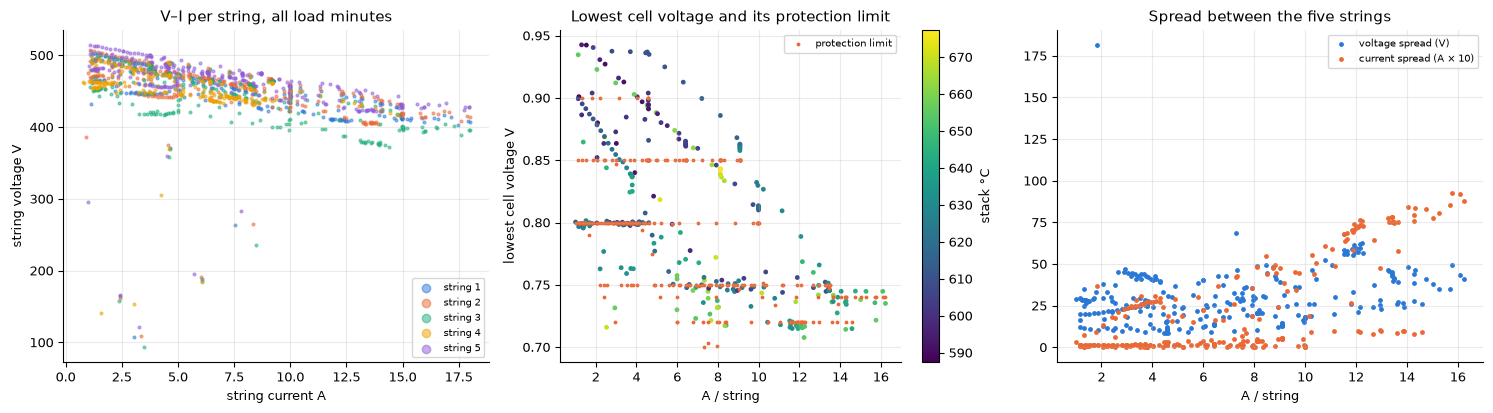

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for i, (ic, vc) in enumerate(zip(I_COLS, V_COLS)):
    x = s[[ic, vc]].dropna()
    x = x[x[ic] > 0.5]
    ax[0].scatter(
        x[ic], x[vc], s=4, color=STRING_COLORS[i], alpha=0.5, label=f"string {i + 1}"
    )
ax[0].set_xlabel("string current A")
ax[0].set_ylabel("string voltage V")
ax[0].legend(fontsize=7, markerscale=3)
ax[0].set_title("V–I per string, all load minutes")
x = s[["I_string_A", "V_cell_min", "V_cell_min_sp", "T_stack_C"]].dropna()
sc = ax[1].scatter(x.I_string_A, x.V_cell_min, c=x.T_stack_C, s=6, cmap="viridis")
ax[1].scatter(
    x.I_string_A, x.V_cell_min_sp, s=3, color="#eb6834", label="protection limit"
)
plt.colorbar(sc, ax=ax[1], label="stack °C")
ax[1].set_xlabel("A / string")
ax[1].set_ylabel("lowest cell voltage V")
ax[1].legend(fontsize=7)
ax[1].set_title("Lowest cell voltage and its protection limit")
imb = s[I_COLS].max(axis=1) - s[I_COLS].min(axis=1)
ax[2].scatter(
    s.I_string_A,
    s[V_COLS].max(axis=1) - s[V_COLS].min(axis=1),
    s=6,
    color="#2a78d6",
    label="voltage spread (V)",
)
ax[2].scatter(
    s.I_string_A, imb * 10, s=6, color="#eb6834", label="current spread (A × 10)"
)
ax[2].set_xlabel("A / string")
ax[2].set_title("Spread between the five strings")
ax[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "electrical.png", dpi=130)
plt.show()

### 4.2 Does the cell-voltage limit stop the current?

For each run: the lowest cell voltage at the highest current, the limit in force, and the margin. A margin near zero
means the current stopped rising because a cell reached its protection limit, not because the operator set it there.

In [9]:
rows = []
for eid, g in s.groupby("episode_id"):
    k = g.I_string_A.idxmax()
    near = (g.V_cell_min - g.V_cell_min_sp) < 0.01
    rows.append(
        {
            "episode_id": eid,
            "I_max_A": g.I_string_A.max(),
            "V_cell_min_at_Imax": g.V_cell_min.loc[k],
            "limit_at_Imax": g.V_cell_min_sp.loc[k],
            "margin_mV": 1000 * (g.V_cell_min.loc[k] - g.V_cell_min_sp.loc[k]),
            "minutes_within_10mV_of_limit": int(near.sum()),
            "limit_values": ", ".join(
                f"{v:.2f}" for v in sorted(g.V_cell_min_sp.round(2).unique())
            ),
        }
    )
lim = pd.DataFrame(rows).set_index("episode_id")
lim.round(3).to_csv(OUT / "cell_voltage_limit.csv")
lim.round(3)

,I_max_A,V_cell_min_at_Imax,limit_at_Imax,margin_mV,minutes_within_10mV_of_limit,limit_values
episode_id,,,,,,
20260313_1003_Part,4.581,0.898,0.90,-1.975,5,0.90
20260313_1326_Part,8.316,0.833,0.85,-16.527,9,0.85
20260319_1020_Part,6.420,0.861,0.85,11.223,0,0.85
20260319_1531_Part,9.080,0.858,0.85,7.758,3,0.85
20260324_0854_Part,14.582,0.715,0.72,-5.182,6,"0.72, 0.73, 0.75, 0.80, 0.85"
20260324_1354_Part,8.406,0.717,0.72,-2.525,20,"0.70, 0.72, 0.73, 0.74, 0.75, 0.79, 0.80"
20260325_0818_Part,11.647,0.715,0.72,-5.023,30,"0.72, 0.73, 0.75, 0.77, 0.80"
20260325_1017_Part,12.265,0.717,0.72,-3.420,30,"0.72, 0.75, 0.79, 0.80"
20260325_1430_Part,16.228,0.735,0.74,-4.935,34,"0.74, 0.75, 0.80"


### 4.3 Balance between strings

Median current and voltage of each string relative to the mean of the five, over load minutes above 5 A.

In [10]:
x = s[s.I_string_A > 5]
bal = pd.DataFrame(
    {
        "current_vs_mean_pct": (
            (x[I_COLS].div(x[I_COLS].mean(axis=1), axis=0) - 1) * 100
        )
        .median()
        .values,
        "voltage_vs_mean_pct": (
            (x[V_COLS].div(x[V_COLS].mean(axis=1), axis=0) - 1) * 100
        )
        .median()
        .values,
        "lowest_cell_V_median": [x[c].median() for c in ss.CELL],
    },
    index=pd.Index(list(ss.STRINGS), name="string"),
)
bal.round(2).to_csv(OUT / "string_balance.csv")
bal.round(2)

,current_vs_mean_pct,voltage_vs_mean_pct,lowest_cell_V_median
string,,,
1,1.63,-0.30,0.77
2,1.46,0.23,0.79
3,1.61,-2.15,0.78
4,-0.08,-0.70,0.75
5,-0.16,2.76,0.78


## 5. Heating under load

### 5.1 Stack temperature

With current flowing the stack produces heat (the losses in the cells), so it warms even with the heater trimmed down.
Rate of the stack median and the hottest thermocouple per run, and the stack rate against current over all load minutes.

In [11]:
rows = []
for eid, g in s.groupby("episode_id"):
    rows.append(
        {
            "episode_id": eid,
            "minutes": len(g),
            "I_mean_A": g.I_string_A.mean(),
            "T_rise_K": g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0],
            "rate_C_per_h": (g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0])
            / (len(g) / 60),
            "rate_20min_max": g.dTdt_20min_C_per_h.max(),
            "hottest_TC_max_C": g.T_tc_max_C.max(),
            "spread_median_K": g.T_spread_K.median(),
            "inlet_lead_median_K": g.T_inlet_lead_K.median(),
            "EAPH_start_kW": g.P_EAPH_kW.iloc[:3].mean(),
            "EAPH_end_kW": g.P_EAPH_kW.iloc[-3:].mean(),
        }
    )
th = pd.DataFrame(rows).set_index("episode_id")
th.round(1).to_csv(OUT / "heating.csv")
th.round(1)

,minutes,I_mean_A,T_rise_K,rate_C_per_h,rate_20min_max,hottest_TC_max_C,spread_median_K,inlet_lead_median_K,EAPH_start_kW,EAPH_end_kW
episode_id,,,,,,,,,,
20260313_1003_Part,8,3.3,7.5,56.0,39.1,619.3,27.3,-1.7,4.5,3.4
20260313_1326_Part,17,6.0,22.5,79.4,96.2,696.8,29.4,-16.6,12.6,4.2
20260319_1020_Part,17,5.0,18.9,66.8,75.8,630.4,25.4,-8.3,6.7,4.7
20260319_1531_Part,18,6.7,22.7,75.7,110.6,657.1,60.0,-43.2,5.2,7.5
20260324_0854_Part,32,9.1,58.3,109.4,140.6,694.8,48.4,-27.9,9.3,16.7
20260324_1354_Part,43,4.7,46.4,64.8,87.7,701.0,50.6,-38.6,13.6,14.9
20260325_0818_Part,33,5.8,29.7,53.9,64.1,652.2,32.8,-23.6,14.7,2.8
20260325_1017_Part,33,8.2,42.6,77.4,96.6,679.6,40.5,-29.3,13.6,15.0
20260325_1430_Part,44,10.9,88.0,119.9,143.2,707.9,42.8,-23.1,12.8,17.5


In [12]:
x = s[["I_string_A", "dTdt_20min_C_per_h", "P_stack_kW", "P_EAPH_kW"]].dropna()
k1, k0 = np.polyfit(x.I_string_A, x.dTdt_20min_C_per_h, 1)
print(
    f"stack rate ≈ {k0:.0f} + {k1:.1f} °C/h per A/string (R² "
    f"{np.corrcoef(x.I_string_A, x.dTdt_20min_C_per_h)[0, 1] ** 2:.2f}, "
    f"{len(x)} minutes)"
)

stack rate ≈ 44 + 5.2 °C/h per A/string (R² 0.43, 265 minutes)


### 5.2 Exhaust temperature and the 200 °C trip

`TIRZ_8_1_10` measures the exhaust after the afterburner. Its trip value was 200 °C from 2026-01-28 to 03-27, and
every load run in the data falls in that period. The table gives the exhaust at load start, its rate during load,
the time from load start to 200 °C, and whether the 200 °C is crossed after the load has already stopped.

In [13]:
rows = []
for _, r in pl.iterrows():
    g = d[d.episode_id == r.episode_id]
    w = d.loc[g.index[0] : g.index[-1] + POST]
    hit = w.exhaust_C[w.exhaust_C >= EXH_LIMIT - 0.5]
    rows.append(
        {
            "episode_id": r.episode_id,
            "exhaust_start_C": g.exhaust_C.iloc[0],
            "exhaust_end_of_load_C": g.exhaust_C.iloc[-1],
            "exhaust_rate_C_per_min": (g.exhaust_C.iloc[-1] - g.exhaust_C.iloc[0])
            / len(g),
            "minutes_to_200C": (hit.index[0] - g.index[0]).total_seconds() / 60
            if len(hit)
            else np.nan,
            "reached_after_load_end": bool(len(hit) and hit.index[0] > g.index[-1]),
            "exhaust_max_C": w.exhaust_C.max(),
            "afterburner_max_C": w.TIRC_5_09.max(),
            "NG_at_end_ln_min": g.fuel.iloc[-1],
        }
    )
ex = pd.DataFrame(rows).set_index("episode_id")
ex.round(1).to_csv(OUT / "exhaust.csv")
ex.round(1)

,exhaust_start_C,exhaust_end_of_load_C,exhaust_rate_C_per_min,minutes_to_200C,reached_after_load_end,exhaust_max_C,afterburner_max_C,NG_at_end_ln_min
episode_id,,,,,,,,
20260313_1003_Part,118.6,123.0,0.5,40.0,True,237.0,772.2,140.0
20260313_1326_Part,131.1,182.4,3.0,19.0,True,200.5,805.8,140.0
20260319_1020_Part,118.3,165.9,2.8,30.0,True,229.9,819.5,100.3
20260319_1531_Part,127.6,183.9,3.1,NaN,False,199.5,786.2,140.0
20260324_0854_Part,99.9,196.7,3.0,35.0,True,237.0,771.2,72.1
20260324_1354_Part,107.9,195.9,2.0,54.0,True,212.3,751.8,46.0
20260325_0818_Part,108.8,101.6,-0.2,NaN,False,138.2,718.6,82.5
20260325_1017_Part,111.0,152.4,1.3,NaN,False,197.4,718.2,32.5
20260325_1430_Part,104.7,184.9,1.8,66.0,True,216.8,786.4,130.0


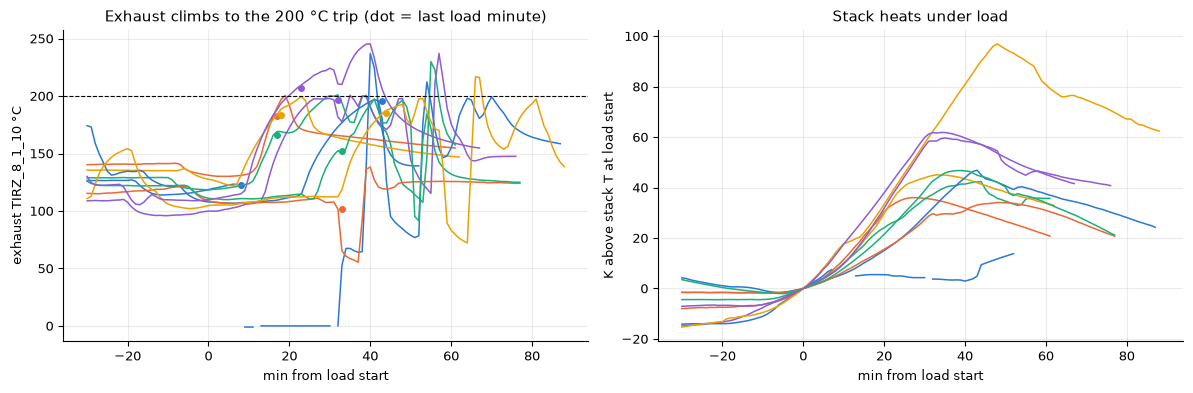

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (_, r), col in zip(pl.iterrows(), STRING_COLORS * 2):
    g = d[d.episode_id == r.episode_id]
    w = d.loc[g.index[0] - PRE : g.index[-1] + POST]
    m = (w.index - g.index[0]).total_seconds() / 60
    ax[0].plot(m, w.exhaust_C, color=col, lw=1.1)
    ax[0].plot(len(g), g.exhaust_C.iloc[-1], "o", color=col, ms=4)
    ax[1].plot(m, w.T_stack_C - g.T_stack_C.iloc[0], color=col, lw=1.1)
ax[0].axhline(EXH_LIMIT, color="k", lw=0.8, ls="--")
ax[0].set_xlabel("min from load start")
ax[0].set_ylabel("exhaust TIRZ_8_1_10 °C")
ax[0].set_title("Exhaust climbs to the 200 °C trip (dot = last load minute)")
ax[1].set_xlabel("min from load start")
ax[1].set_ylabel("K above stack T at load start")
ax[1].set_title("Stack heats under load")
fig.tight_layout()
fig.savefig(OUT / "exhaust_and_heating.png", dpi=130)
plt.show()

## 6. Fuel, air and heater during load

Natural gas (FIRC 1.4), POx air (FIRC 1.2), cathode air, the EAPH heater, the fuel utilisation the PLC reports for
the worst and best string (`PLC_pv_rFU_Worst / best`), and an approximate DC efficiency: stack DC power divided by
the natural-gas flow × 0.598 kW per ln/min (lower heating value of methane; the real gas composition is not logged).

In [15]:
FL = {
    "NG ln/min": "fuel",
    "POx air ln/min": "pox_air",
    "cathode air ln/min": "air_flow",
    "EAPH kW": "P_EAPH_kW",
    "EAPH target °C": "eaph_sp_C",
    "FU worst %": "FU_worst",
    "FU best %": "FU_best",
    "DC efficiency": "eff_dc",
    "N2 ln/min": "N2",
    "H2 ln/min": "H2",
}
band = pd.cut(s.I_string_A, [1, 4, 8, 12, 16, 20])
fl = s.groupby(band)[list(FL.values())].median()
fl.columns = list(FL)
fl.insert(0, "minutes", s.groupby(band).size())
fl.round(2).to_csv(OUT / "fuel_air_by_current.csv")
fl.round(2)

,minutes,NG ln/min,POx air ln/min,cathode air ln/min,EAPH kW,EAPH target °C,FU worst %,FU best %,DC efficiency,N2 ln/min,H2 ln/min
I_string_A,,,,,,,,,,,
"(1, 4]",86,129.98,327.89,8998.48,11.14,590.00,9.11,0.0,0.08,0.0,0.0
"(4, 8]",80,124.99,287.93,8999.47,7.23,600.00,19.85,0.0,0.18,0.0,0.0
"(8, 12]",62,139.98,311.84,8999.97,6.26,600.00,29.50,0.0,0.25,0.0,0.0
"(12, 16]",38,150.00,382.74,9001.30,11.09,610.00,38.63,0.0,0.31,0.0,0.0
"(16, 20]",2,160.01,383.79,9033.88,16.38,604.25,43.24,0.0,0.35,0.0,0.0


NG ≈ 107 + 3.2 ln/min per A/string (R² 0.33); FU worst ≈ 2.7 % per A/string


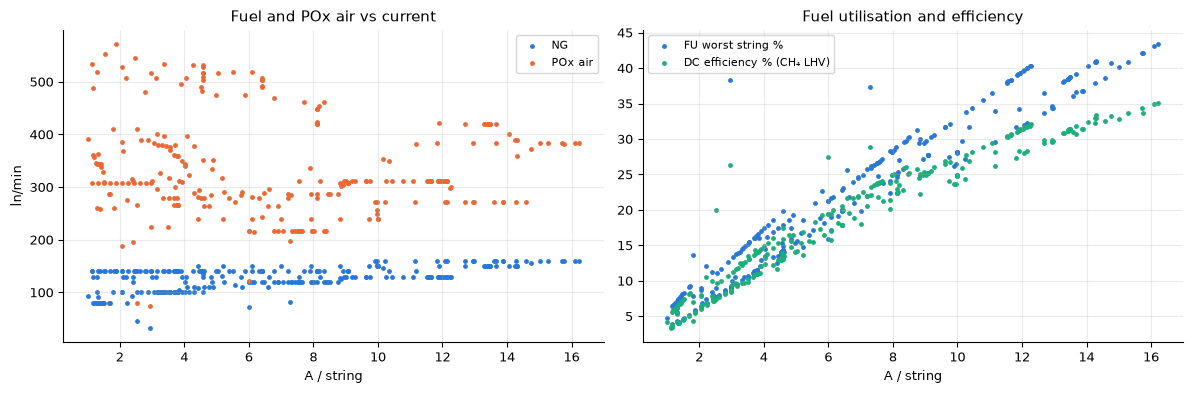

In [16]:
x = s[["I_string_A", "fuel", "FU_worst"]].dropna()
x = x[x.fuel > 5]
k1, k0 = np.polyfit(x.I_string_A, x.fuel, 1)
print(
    f"NG ≈ {k0:.0f} + {k1:.1f} ln/min per A/string (R² "
    f"{np.corrcoef(x.I_string_A, x.fuel)[0, 1] ** 2:.2f}); "
    f"FU worst ≈ {np.polyfit(x.I_string_A, x.FU_worst, 1)[0]:.1f} % per A/string"
)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(s.I_string_A, s.fuel, s=6, color="#2a78d6", label="NG")
ax[0].scatter(s.I_string_A, s.pox_air, s=6, color="#eb6834", label="POx air")
ax[0].set_xlabel("A / string")
ax[0].set_ylabel("ln/min")
ax[0].legend(fontsize=8)
ax[0].set_title("Fuel and POx air vs current")
ax[1].scatter(s.I_string_A, s.FU_worst, s=6, color="#2a78d6", label="FU worst string %")
ax[1].scatter(
    s.I_string_A,
    s.eff_dc * 100,
    s=6,
    color="#1baf7a",
    label="DC efficiency % (CH₄ LHV)",
)
ax[1].set_xlabel("A / string")
ax[1].legend(fontsize=8)
ax[1].set_title("Fuel utilisation and efficiency")
fig.tight_layout()
fig.savefig(OUT / "fuel_air.png", dpi=130)
plt.show()

## 7. How runs end, and how far rated power is

### 7.1 Ends

In [17]:
end = inv[["minutes", "I_max_A", "exhaust_max_C", "ends_in_trip", "end_event", "next"]]
print(
    "runs ended in a safety trip (library flag): "
    f"{int(inv.ends_in_trip.sum())} of {len(inv)}; "
    "runs whose exhaust reached 200 °C within 45 min of the end: "
    f"{int((ex.exhaust_max_C >= EXH_LIMIT - 0.5).sum())}"
)
end

runs ended in a safety trip (library flag): 8 of 10; runs whose exhaust reached 200 °C within 45 min of the end: 7


,minutes,I_max_A,exhaust_max_C,ends_in_trip,end_event,next
episode_id,,,,,,
20260313_1003_Part,8,4.580847,123.348690,False,10:10 Valve change only,Thermal adjustment
20260313_1326_Part,17,8.315999,200.494508,True,"13:45 Power cut at trip value, gas unchanged",Shut-down
20260319_1020_Part,17,6.420062,200.340643,True,10:36 Valve change only; 10:40 Valve change on...,Thermal adjustment
20260319_1531_Part,18,9.079714,199.496898,True,"15:54 Power cut at trip value, gas unchanged",Shut-down
20260324_0854_Part,32,14.582167,200.686973,True,09:25 EMERGENCY PURGE; 09:29 Load / heater off...,Thermal adjustment
20260324_1354_Part,43,8.405588,212.295722,True,14:36 EMERGENCY PURGE; 14:38 EMERGENCY STOP,Thermal adjustment
20260325_0818_Part,33,11.646808,138.230435,True,08:50 EMERGENCY STOP,Thermal adjustment
20260325_1017_Part,33,12.264546,197.388685,True,"10:49 Gas to purge, heater kept on; 10:58 Powe...",Thermal adjustment
20260325_1430_Part,44,16.228493,197.692488,True,"15:18 Gas to purge, heater kept on",Shut-down


### 7.2 Rated power

The V–I–T planes of §4.1 extrapolated to 30 A, and the same plane fitted to the lowest cell voltage, at a stack
temperature of 650 °C (the level reached late in the longer runs). This is a straight-line extrapolation from
≤ 16 A, so it is indicative only.

In [18]:
x = s[["I_string_A", "V_cell_min", "T_stack_C"]].dropna()
x = x[x.I_string_A > 2]
(c0, rc, kc), r2c = plane(x.V_cell_min.values, x.I_string_A.values, x.T_stack_C.values)
T_X = 650.0
v_str30 = vi.V0_V - 30 * vi.R_ohm + vi.kT_V_per_K * (T_X - T_REF)


def v_cell(i):
    return c0 - rc * i + kc * (T_X - T_REF)


print(
    f"lowest cell: V ≈ {c0:.3f} − {rc * 1000:.1f} mV/A·I + {kc * 1000:.2f} mV/K·(T − "
    f"620)  (R² {r2c:.2f})"
)
rated = pd.Series(
    {
        "highest current reached (A / string)": (
            f"{s.I_string_A.max():.1f} ({s.I_string_A.max() / I_RATED:.0%} of 30 A)"
        ),
        "highest DC power (kW)": (
            f"{s.P_stack_kW.max():.1f} ({s.P_stack_kW.max() / P_RATED_DC:.0%} of 60 kW)"
        ),
        "string voltage at 30 A, 650 °C (V)": f"{v_str30.mean():.0f}",
        "DC power at 30 A, 650 °C (kW)": f"{v_str30.sum() * 30 / 1000:.0f}",
        "lowest cell voltage at 30 A, 650 °C (V)": f"{v_cell(30):.2f}",
        "current where the lowest cell reaches 0.72 V at 650 °C (A)": (
            f"{(c0 + kc * (T_X - T_REF) - 0.72) / rc:.1f}"
        ),
        "current where the lowest cell reaches 0.80 V at 650 °C (A)": (
            f"{(c0 + kc * (T_X - T_REF) - 0.80) / rc:.1f}"
        ),
    },
    name="value",
)
rated.to_frame()

lowest cell: V ≈ 0.872 − 8.9 mV/A·I + -0.66 mV/K·(T − 620)  (R² 0.42)


,value
highest current reached (A / string),16.2 (54% of 30 A)
highest DC power (kW),33.6 (56% of 60 kW)
"string voltage at 30 A, 650 °C (V)",344
"DC power at 30 A, 650 °C (kW)",52
"lowest cell voltage at 30 A, 650 °C (V)",0.59
current where the lowest cell reaches 0.72 V at 650 °C (A),14.9
current where the lowest cell reaches 0.80 V at 650 °C (A),5.9


## 8. Signal levels by current band

Median levels during load per current band, and the per-minute noise σ (robust, as in the other notebooks). With
the current ramping almost all the time, σ includes some of the ramp.

In [19]:
LEV = {
    "stack DC kW": "P_stack_kW",
    "string V (mean)": "V_string_mean",
    "lowest cell V": "V_cell_min",
    "stack °C": "T_stack_C",
    "stack rate °C/h": "dTdt_20min_C_per_h",
    "TC spread K": "T_spread_K",
    "inlet lead K": "T_inlet_lead_K",
    "exhaust °C": "exhaust_C",
    "afterburner °C": "TIRC_5_09",
    "reformer in °C": "TIRC_3_07",
    "reformer out °C": "TIRC_3_15",
    "NG ln/min": "fuel",
    "POx air ln/min": "pox_air",
    "cathode air ln/min": "air_flow",
    "PIR_2_02": "P_air_in",
    "EAPH kW": "P_EAPH_kW",
    "FU worst %": "FU_worst",
}
lev = s.groupby(band)[list(LEV.values())].median()
lev.columns = list(LEV)
lev.insert(0, "minutes", s.groupby(band).size())
lev.round(2).to_csv(OUT / "levels_by_current.csv")
lev.round(2)

,minutes,stack DC kW,string V (mean),lowest cell V,stack °C,stack rate °C/h,TC spread K,inlet lead K,exhaust °C,afterburner °C,reformer in °C,reformer out °C,NG ln/min,POx air ln/min,cathode air ln/min,PIR_2_02,EAPH kW,FU worst %
I_string_A,,,,,,,,,,,,,,,,,,
"(1, 4]",86,5.97,476.48,0.84,616.22,52.30,31.47,-23.72,110.03,751.89,749.00,612.15,129.98,327.89,8998.48,20.59,11.14,9.11
"(4, 8]",80,13.91,463.14,0.80,617.63,70.42,33.38,-22.66,122.06,746.72,706.21,618.43,124.99,287.93,8999.47,21.65,7.23,19.85
"(8, 12]",62,21.16,445.17,0.75,627.09,95.12,52.08,-35.65,113.88,733.27,708.08,611.80,139.98,311.84,8999.97,22.25,6.26,29.50
"(12, 16]",38,28.23,420.51,0.74,642.57,125.41,68.73,-43.79,114.98,709.46,717.96,614.20,150.00,382.74,9001.30,23.03,11.09,38.63
"(16, 20]",2,33.49,416.84,0.74,652.96,141.32,82.41,-57.00,124.61,721.86,720.87,613.50,160.01,383.79,9033.88,23.57,16.38,43.24


In [20]:
noise = pd.Series(
    {k: ss.robust_sigma(s[c]) for k, c in LEV.items()}, name="noise_sigma_per_min"
)
noise.round(3).to_frame()

,noise_sigma_per_min
stack DC kW,0.514
string V (mean),2.295
lowest cell V,0.005
stack °C,0.540
stack rate °C/h,1.835
TC spread K,0.894
inlet lead K,0.803
exhaust °C,0.616
afterburner °C,3.097
reformer in °C,2.177


## 9. Summary

In [21]:
summary = pd.Series(
    {
        "Part load minutes": (
            f"{len(s)} ({len(s) / 60:.1f} h) in {len(pl)} runs of "
            f"{inv.minutes.min()}–{inv.minutes.max()} min"
        ),
        "Highest current / power": (
            f"{s.I_string_A.max():.1f} A / string, {s.P_stack_kW.max():.1f} kW DC"
        ),
        "Ramp-up per string, median / p95 / max": (
            f"{up_all.median():.2f} / {up_all.quantile(0.95):.2f} / "
            f"{up_all.max():.2f} A/min"
        ),
        "Runs ended by a safety trip": f"{int(inv.ends_in_trip.sum())} of {len(inv)}",
        "Lowest cell voltage at peak current": (
            f"{lim.V_cell_min_at_Imax.min():.2f}–{lim.V_cell_min_at_Imax.max():.2f} V "
            f"(limit {lim.limit_at_Imax.min():.2f}–{lim.limit_at_Imax.max():.2f} V)"
        ),
        "Stack heating under load": (
            f"{th.rate_C_per_h.min():.0f}–{th.rate_C_per_h.max():.0f} °C/h per run"
        ),
    },
    name="value",
)
summary.to_frame()

,value
Part load minutes,268 (4.5 h) in 10 runs of 8–44 min
Highest current / power,"16.2 A / string, 33.6 kW DC"
"Ramp-up per string, median / p95 / max",0.42 / 0.90 / 0.92 A/min
Runs ended by a safety trip,8 of 10
Lowest cell voltage at peak current,0.71–0.90 V (limit 0.72–0.90 V)
Stack heating under load,54–120 °C/h per run


### Findings

**How much**
- Part load is **268 min (4.5 h, 0.5 %)** of the 39 logged days: **10 runs of 8–44 min**, all in March 2026
  (03-13, 03-19, 03-24, 03-25, 03-30). The highest current is **16.2 A per string (54 % of 30 A)** and the
  highest DC power **33.6 kW (56 % of 60 kW)**, both on 03-25 at 15:04.
- The PLC monitor shows **no load on 2026-03-20**. The 18.8 A listed for that day in `operational-modes.md` §4.4
  comes from the `EIRC_4X` columns that are corrupted on that day (see Open points).
- Every run starts from a hot stack (588–655 °C) in Hot standby (Part load only follows Hot standby; the last 15 min
  before load are *pre-load*), after the switch from forming gas to natural gas (start-up notebook §8).

**Load profile and ramps (§3)**
- The current climbs in steps almost the whole run: 239 of the 268 minutes are labelled *Load ramp-up*, 18 *Steady
  load*, 11 *Load ramp-down*. Ramp-up per string: median **0.42 A/min**, p95 0.90, max **0.92 A/min**, so always below the 1 A/min limit.
  On 03-30 the ramp is 0.19 A/min. The power ramps at up to ~2 kW/min.
- At the end the load falls either in a **step of 8 A within 10 s** (03-24 08:54, 03-25 08:18, the emergency
  cases) or at ~1–2 A/min over 2–10 min. On the 1-min data, 20 minutes exceed 1 A/min, all on the way down.

**Electrical behaviour (§4)**
- String voltage ≈ **V₀ − R·I + k_T·(T − 620 °C)**, with V₀ = 479–502 V, R = **3.7–5.9 Ω per string** (string 3
  highest) and k_T ≈ 0.1–0.2 V/K (R² 0.45–0.67). At 15 A and 620 °C a string gives 396–426 V.
- The five strings share the current within ±2 %. String 3 runs 2.2 % below the mean voltage and string 5 2.8 %
  above.
- **The lowest cell voltage sets the ceiling.** It falls from ~0.96 V at open circuit to its protection limit
  within minutes. The limit was 0.90 V on 03-13, 0.85 V on 03-13/03-19 and 0.80 V on 03-30. On 03-24/25 the
  operator lowered it step by step (**0.80 → 0.75 → 0.72 V**) to let more current through. In the five 03-24/25
  runs the lowest cell sits **within 10 mV of the limit** for 6–34 min, and every peak current (8.4–16.2 A) is
  reached at 0.715–0.735 V. The current stops rising because the weakest cell reaches its limit, not because of the
  ramp rule.

**Heating and the exhaust trip (§5)**
- The stack heats under load by **+7 to +88 K per run**, at a mean 54–120 °C/h (20-min peak 143 °C/h). The rate grows
  with current: ≈ 44 + 5.2 °C/h per A per string (R² 0.43). The hottest thermocouple reaches **708 °C**, and the
  stack-module safety sensor `TIRZ_8_1_3` reaches **694 °C** against its 720 °C trip. The heater stays on at
  3–22 kW throughout.
- The cathode air (9 000 ln/min) cools the inlet side: inlet lead −2 to −48 K, spread 25–74 K.
- **Exhaust `TIRZ_8_1_10`** starts at 100–131 °C and climbs **2–4 °C/min** under load. In 7 of 10 runs it reaches
  the **200 °C** trip value within 45 min, often a few minutes *after* the current has dropped, while natural gas
  still feeds the afterburner. On 03-30 it reaches 245 °C with no trip, because the limit was raised to 300 °C
  on 03-27.

**How runs end (§7.1)**
- **Every run leaves Part load for a Thermal adjustment (7 of 10, a no-load cool-back of the hot stack) or a Shut-down
  (3 of 10: 03-13 13:26, 03-19 15:31, 03-25 14:30).** The ramp-down before a Thermal adjustment stays Part load.
- **8 of 10 runs end in a safety trip**: power cut at the 200 °C exhaust value (03-13, 03-19, 03-25 10:58),
  EMERGENCY PURGE + STOP (03-24 ×2), EMERGENCY STOP (03-25 08:50, 15:28). The 03-25 08:50 stop comes with the
  exhaust at only 138 °C, so it has a different cause that the logged columns do not show.

**Fuel, air and efficiency (§6)**
- Natural gas is set in steps by the operator (130 → 140 → 150 → 160 ln/min), loosely tied to current. POx air
  is 290–480 ln/min and cathode air 9 000 ln/min.
- Fuel utilisation (worst string) rises from **9 % at 1–4 A to 43 % at 16–20 A** (≈ 2.7 % per A). The *best
  string* utilisation reads 0 throughout.
- Approximate DC efficiency on the methane heating value: **8 % → 35 %** across the current bands.

**Rated power (§7.2)**
- Extrapolating the fitted lines to **30 A at 650 °C**: ~344 V per string, so **≈ 52 kW DC**, still below the
  60 kW rating. The lowest cell would sit near **0.59 V**, far below any limit used (0.72–0.90 V). The same fit puts
  the 0.72 V limit at **≈ 15 A**, matching the observed peaks.
- Caveat: the lowest-cell fit has a negative temperature term (−0.66 mV/K). This is not physical; it appears because
  the controller holds that cell at its limit while the stack warms. Treat these numbers as indicative.

### For the synthetic-data generator
| Parameter | Value |
|---|---|
| Before load | NG + POx air on and forming gas off 8–22 min earlier (Hot standby / pre-load; start-up notebook) |
| Current | staircase ramp 0.3–0.9 A/min per string (never > 0.92), short holds; 0.19 A/min variant |
| Ceiling | current stops where the lowest cell reaches its limit (0.72–0.90 V): ≈ 15 A at 0.72 V |
| String voltage | V₀ − R·I + k_T·(T − 620): V₀ 479–502 V, R 3.7–5.9 Ω, k_T 0.1–0.2 V/K; strings within ±2 % current |
| Stack heating | ≈ 44 + 5.2 °C/h per A/string; inlet lead −20…−50 K; hottest TC up to ~710 °C |
| Exhaust | from ~110 °C, +2–4 °C/min under load; trip at 200 °C (300 °C from 03-27) |
| End of run | trip (8 of 10): step of ~8 A in 10 s, or 1–2 A/min over a few minutes; then Thermal adjustment (cool-back, 7 of 10) or Shut-down (3 of 10) |
| Fuel | NG 130–160 ln/min (operator steps), POx air 290–480, cathode air 9 000 ln/min; FU worst ≈ 2.7 % per A |

### Open points
1. **Rated power** (decision D3 still open): the data reach 54 % of the rated current and point to ≈ 52 kW DC and a
   0.59 V weakest cell at 30 A. This supports leaving rated power out of the generator, or taking it from design
   values rather than from the data.
2. **`operational-modes.md` §4.4** lists 18.8 A on 2026-03-20; the PLC monitor shows no load that day. Correct the
   table (and the 18.8 A / 63 % in §4.6)?
3. **2026-03-25 08:50 EMERGENCY STOP** at an exhaust of 138 °C: the cause is not in the logged columns (S-PLC log
   needed).
4. **Exhaust limit 200 → 300 °C on 03-27**: the generator needs to know which limit applies. In the 200 °C period
   no run's exhaust went above 240 °C, so under the 300 °C limit those exhaust trips would not have fired.